In [300]:
import pandas as pd
import matplotlib.pyplot as plt

In [301]:
df=pd.read_csv("riceClassification.csv")

In [302]:
df.head()

,id,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,EquivDiameter,Extent,Perimeter,Roundness,AspectRation,Class
0,1,4537,92.229316,64.012769,0.719916,4677,76.004525,0.657536,273.085,0.764510,1.440796,1
1,2,2872,74.691881,51.400454,0.725553,3015,60.471018,0.713009,208.317,0.831658,1.453137,1
2,3,3048,76.293164,52.043491,0.731211,3132,62.296341,0.759153,210.012,0.868434,1.465950,1
3,4,3073,77.033628,51.928487,0.738639,3157,62.551300,0.783529,210.657,0.870203,1.483456,1
4,5,3693,85.124785,56.374021,0.749282,3802,68.571668,0.769375,230.332,0.874743,1.510000,1


In [303]:
df.tail()

,id,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,EquivDiameter,Extent,Perimeter,Roundness,AspectRation,Class
18180,18181,5853,148.624571,51.029281,0.939210,6008,86.326537,0.498594,332.960,0.663444,2.912535,0
18181,18182,7585,169.593996,58.141659,0.939398,7806,98.272692,0.647461,385.506,0.641362,2.916910,0
18182,18183,6365,154.777085,52.908085,0.939760,6531,90.023162,0.561287,342.253,0.682832,2.925396,0
18183,18184,5960,151.397924,51.474600,0.940427,6189,87.112041,0.492399,343.371,0.635227,2.941216,0
18184,18185,6134,153.081981,51.590606,0.941500,6283,88.374495,0.489975,338.613,0.672274,2.967245,0


In [304]:
df.shape

(18185, 12)

In [305]:
df.isna().sum()

id                 0
Area               0
MajorAxisLength    0
MinorAxisLength    0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Perimeter          0
Roundness          0
AspectRation       0
Class              0
dtype: int64

In [306]:
df.columns

Index(['id', 'Area', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity',
       'ConvexArea', 'EquivDiameter', 'Extent', 'Perimeter', 'Roundness',
       'AspectRation', 'Class'],
      dtype='str')

In [307]:
df=df.drop_duplicates()

In [308]:
df1=df["Class"].value_counts()
df1

Class
1    9985
0    8200
Name: count, dtype: int64

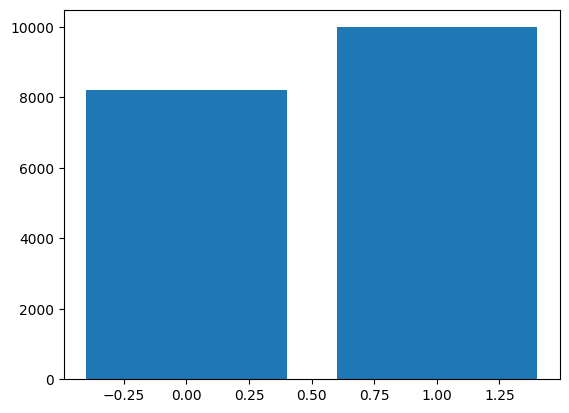

In [309]:
plt.bar(df1.index,df1.values)
plt.show()

In [310]:
x=df.drop(columns=["id","Class"])
y=df["Class"]

In [311]:
from sklearn.model_selection import train_test_split

In [312]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=.25,random_state=42)

In [313]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()

In [314]:
scaler.fit(x_train)

StandardScaler()

In [315]:
x_train=scaler.transform(x_train)
x_test=scaler.transform(x_test)

In [316]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
knn=KNeighborsClassifier()
svm=SVC()
nb=GaussianNB()
dt=DecisionTreeClassifier()

lst=[knn,svm,nb,dt]

In [317]:
for i in lst:
    print("model selection________________",i)
    print(i.fit(x_train,y_train))
    y_pred=i.predict(x_test)


    print("confusion_matrix_______________",i)
    print(confusion_matrix(y_test,y_pred))


    print("accuracy score_____________",i)
    print(accuracy_score(y_test,y_pred))

model selection________________ KNeighborsClassifier()
KNeighborsClassifier()
confusion_matrix_______________ KNeighborsClassifier()
[[2017   25]
 [  26 2479]]
accuracy score_____________ KNeighborsClassifier()
0.9887838135034088
model selection________________ SVC()
SVC()
confusion_matrix_______________ SVC()
[[2014   28]
 [  22 2483]]
accuracy score_____________ SVC()
0.9890037387288322
model selection________________ GaussianNB()
GaussianNB()
confusion_matrix_______________ GaussianNB()
[[1987   55]
 [   6 2499]]
accuracy score_____________ GaussianNB()
0.9865845612491753
model selection________________ DecisionTreeClassifier()
DecisionTreeClassifier()
confusion_matrix_______________ DecisionTreeClassifier()
[[2011   31]
 [  31 2474]]
accuracy score_____________ DecisionTreeClassifier()
0.9863646360237519
